# P6. 베이즈 정리: 사전 × 우도 → 사후

**목표**
- 베이즈 정리의 네 항(사전, 우도, 증거, 사후)이 각각 무엇인지 1,000 명 점 그림으로 봅니다.
- 같은 검사라도 **기저율**(사전확률)에 따라 결론이 크게 달라지는 이유를 봅니다.
- θ 가 연속일 때 "사후 ∝ 사전 × 우도"를 곡선 곱하기로 봅니다.
- 어제의 사후가 오늘의 사전이 되는 **순차 업데이트**를 확인합니다.
- 시퀀싱: P5 의 genotype 우도에 사전확률을 곱해 genotype 사후확률을 구합니다.

**이 노트북이 답하는 질문**: 데이터를 본 뒤 "이 가설이 맞을 확률"은 어떻게 계산하나?

**같이 볼 강의·교재**
- Harvard Stat 110 (Blitzstein), 4강 "Conditional Probability", 5강 "Conditioning Continued, Law of Total Probability" [2]
- Downey, *Think Bayes* 2판, 2장 "Bayes's Theorem" [3]
- BDA3, 1.3 절 "Bayesian inference", 1.4 절 "Discrete examples: genetics and spell checking" [1]
- McElreath, *Statistical Rethinking* 2023, 2강 [4]

In [1]:
# 그림 도구 (펼치지 않아도 됩니다). 팔레트: Okabe-Ito, 뜻 고정 — 사전 하늘, 우도 주황, 사후 파랑, 증거 진회색, 핵심 자주
import logging, math, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from scipy import stats, special

warnings.filterwarnings("ignore", category=RuntimeWarning)
COL = dict(prior="#56B4E9", likelihood="#E69F00", posterior="#0072B2", evidence="#374151",
           highlight="#CC79A7", ink="#222222", muted="#6B7280", grid="#E5E7EB", none="#D1D5DB",
           ok="#009E73", alt="#D55E00", ref="#9CA3AF", shade="#F3F4F6")

def apply_theme():
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # 글꼴 대체 경고 숨김
    plt.rcParams.update({
        "font.family": ["Arial", "DejaVu Sans"], "font.size": 10.5, "mathtext.fontset": "dejavusans",
        "axes.titlesize": 11.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
        "axes.titlepad": 10, "axes.labelsize": 10.5, "axes.labelcolor": COL["ink"],
        "axes.edgecolor": "#9CA3AF", "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": False, "grid.color": COL["grid"], "grid.linewidth": 0.8,
        "xtick.color": COL["muted"], "ytick.color": COL["muted"],
        "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
        "legend.frameon": False, "legend.fontsize": 9.5,
        "figure.dpi": 110, "savefig.bbox": "tight", "figure.facecolor": "white"})

def panel(ax, letter, title):
    """왼쪽 정렬 'A   제목'"""
    ax.set_title(f"{letter}   {title}")

def note(ax, x, y, text, **kw):
    """회색 작은 주석"""
    kw.setdefault("fontsize", 9); kw.setdefault("color", COL["muted"])
    return ax.text(x, y, text, **kw)

def callout(ax, x, y, text, **kw):
    """핵심 메시지 한 줄: 자주색 굵은 글씨, 흰 바탕"""
    kw.setdefault("fontsize", 10); kw.setdefault("color", COL["highlight"]); kw.setdefault("fontweight", "semibold")
    kw.setdefault("bbox", dict(facecolor="white", edgecolor="none", pad=1.5, alpha=0.9))
    return ax.text(x, y, text, **kw)

def ygrid(ax):
    ax.yaxis.grid(True); ax.set_axisbelow(True)

def formula_strip(ax, parts, y=0.5, fontsize=17, gap=0.03):
    """수식을 조각으로 그린다. parts = [(mathtext, 색 또는 None, 아래 이름표 또는 None), ...]
    색이 있는 조각은 옅은 배경 상자 + 같은 색 이름표. 아래 그림의 같은 색과 짝을 이룬다."""
    ax.set_axis_off(); fig = ax.figure
    r = fig.canvas.get_renderer(); inv = ax.transAxes.inverted(); x = 0.0; items = []
    for tex, color, label in parts:
        t = ax.text(0, y, tex, fontsize=fontsize, va="center", ha="left",
                    color=color or COL["ink"], transform=ax.transAxes)
        bb = t.get_window_extent(renderer=r).transformed(inv)
        lw = 0.0
        if label:                                          # 이름표가 조각보다 넓으면 그만큼 자리를 더 준다
            lt = ax.text(0, 0, label, fontsize=9.5, fontweight="semibold", transform=ax.transAxes)
            lw = lt.get_window_extent(renderer=r).transformed(inv).width; lt.remove()
        slot = max(bb.width, lw)
        items.append((t, bb, color, label, x + (slot - bb.width) / 2)); x += slot + gap
    shift = (1 - (x - gap)) / 2                            # 가운데 정렬
    for t, bb, color, label, x0 in items:
        t.set_x(x0 + shift)
        if color:
            ax.add_patch(FancyBboxPatch((x0 + shift - 0.006, bb.y0 - 0.04), bb.width + 0.012, bb.height + 0.08,
                                        boxstyle="round,pad=0,rounding_size=0.02", transform=ax.transAxes,
                                        facecolor=color, alpha=0.13, edgecolor="none", zorder=0))
        if label:
            ax.text(x0 + shift + bb.width / 2, bb.y0 - 0.12, label, ha="center", va="top", fontsize=9.5,
                    color=color or COL["muted"], fontweight="semibold", transform=ax.transAxes)

def show_formula(parts, title=None, height=1.5, width=11):
    """수식 조각 그림만 한 장으로"""
    fig, ax = plt.subplots(figsize=(width, height))
    formula_strip(ax, parts)
    if title:
        ax.text(0.5, 1.05, title, ha="center", va="bottom", fontsize=11.5, fontweight="semibold", transform=ax.transAxes)
    plt.show()

def concept_map(nodes, edges, title="Concept map", size=(11, 3.2)):
    """nodes = {key: (x, y, text, color)}, edges = [(from, to, label)] — 상자와 화살표"""
    fig, ax = plt.subplots(figsize=size)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_axis_off()
    boxes = {}
    for k, (x, y, text, c) in nodes.items():
        t = ax.text(x, y, text, ha="center", va="center", fontsize=10, color=COL["ink"], zorder=3,
                    bbox=dict(boxstyle="round,pad=0.45", facecolor=c if c != "white" else "white",
                              alpha=0.25 if c != "white" else 1, edgecolor=c if c != "white" else COL["muted"],
                              linewidth=1.0))
        boxes[k] = t
    fig.canvas.draw(); r = fig.canvas.get_renderer(); inv = ax.transAxes.inverted()
    ext = {}
    for k, t in boxes.items():                             # 상자 크기(축 좌표)
        bb = t.get_bbox_patch().get_window_extent(r).transformed(inv)
        ext[k] = (bb.x0, bb.y0, bb.x1, bb.y1)

    def edge_point(k, dx, dy):
        x0, y0, x1, y1 = ext[k]; cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
        hw, hh = (x1 - x0) / 2 + 0.008, (y1 - y0) / 2 + 0.02
        s = min(hw / abs(dx) if dx else 1e9, hh / abs(dy) if dy else 1e9)
        return cx + dx * s, cy + dy * s

    for a, b, lab in edges:
        (ax0, ay0, ax1, ay1), (bx0, by0, bx1, by1) = ext[a], ext[b]
        ca, cb = ((ax0 + ax1) / 2, (ay0 + ay1) / 2), ((bx0 + bx1) / 2, (by0 + by1) / 2)
        dx, dy = cb[0] - ca[0], cb[1] - ca[1]
        p0 = edge_point(a, dx, dy); p1 = edge_point(b, -dx, -dy)
        ax.annotate("", xy=p1, xytext=p0, xycoords="axes fraction", textcoords="axes fraction",
                    arrowprops=dict(arrowstyle="-|>", color=COL["muted"], lw=1.0, mutation_scale=12,
                                    shrinkA=0, shrinkB=0), zorder=2)
        if lab:
            note(ax, (p0[0] + p1[0]) / 2, (p0[1] + p1[1]) / 2 + 0.05, lab, ha="center", fontsize=8.5,
                 transform=ax.transAxes)
    ax.set_title(title)
    plt.show()

def phred_to_e(q):
    """Phred 점수 → 오류 확률: Q = -10 log10(e) [Cock 2010]"""
    return 10 ** (-np.asarray(q, float) / 10)

apply_theme()

In [2]:
# 이 노트북의 그림 함수
def draw_bayes_reading(prev=0.02, sens=0.90, fpr=0.05, n=1000, seed=0):
    """견본(study_build/_proto_formula.py) 그대로: 1000 명 점 그림 + 각 항에 숫자 넣기"""
    sick = int(round(n * prev)); tp = int(round(sick * sens)); fp = int(round((n - sick) * fpr))
    post = tp / (tp + fp)
    fig = plt.figure(figsize=(11.5, 6.2))
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 3.2], width_ratios=[1.35, 1], hspace=0.25, wspace=0.12)
    axf = fig.add_subplot(gs[0, :])
    formula_strip(axf, [
        (r"$P(\mathrm{sick}\mid +)$", COL["posterior"], "posterior"),
        (r"$=$", None, None),
        (r"$P(+\mid \mathrm{sick})$", COL["likelihood"], "likelihood"),
        (r"$\times$", None, None),
        (r"$P(\mathrm{sick})$", COL["prior"], "prior"),
        (r"$\div$", None, None),
        (r"$P(+)$", COL["evidence"], "all positives"),
    ])
    axf.text(0.5, 1.02, "Bayes' theorem, read piece by piece", ha="center", va="bottom",
             fontsize=11.5, fontweight="semibold", transform=axf.transAxes)
    ax = fig.add_subplot(gs[1, 0]); rng = np.random.default_rng(seed)
    cols = 40; idx = np.arange(n); x, yv = idx % cols, idx // cols
    status = np.full(n, "healthy", dtype=object)
    order = rng.permutation(n); status[order[:sick]] = "sick"
    sick_pos = np.zeros(n, bool); sick_pos[order[:tp]] = True
    healthy_idx = order[sick:]; status[healthy_idx[:fp]] = "fp"
    colour = {"healthy": COL["none"], "sick": COL["prior"], "fp": COL["none"]}
    for k in ("healthy", "fp", "sick"):
        m = status == k
        ax.scatter(x[m], yv[m], s=22, c=colour[k], linewidths=0)
    pos = sick_pos | (status == "fp")
    ax.scatter(x[pos], yv[pos], s=70, facecolors="none", edgecolors=COL["evidence"], linewidths=1.5)
    ax.set_xlim(-1, cols); ax.set_ylim(n // cols, -1); ax.set_axis_off()
    ax.set_title(f"A   {n} people tested")
    ax.text(0, n // cols + 0.6, f"blue = sick ({sick}, {sick - tp} missed by the test)    "
            f"ring = tested positive ({tp + fp}: {tp} sick + {fp} healthy)", fontsize=9, color=COL["muted"], va="top")
    ax = fig.add_subplot(gs[1, 1]); ax.set_axis_off()
    rows = [("prior", COL["prior"], r"$P(\mathrm{sick})$", f"{sick}/{n} = {prev:.2f}", "how common before testing"),
            ("likelihood", COL["likelihood"], r"$P(+\mid \mathrm{sick})$", f"{tp}/{sick} = {sens:.2f}", "rings among the blue dots"),
            ("all positives", COL["evidence"], r"$P(+)$", f"({tp}+{fp})/{n} = {(tp + fp) / n:.3f}", "every ring, sick or not"),
            ("posterior", COL["posterior"], r"$P(\mathrm{sick}\mid +)$", f"{tp}/({tp}+{fp}) = {post:.2f}", "sick among the rings")]
    for i, (name, c, tex, val, meaning) in enumerate(rows):
        yy = 0.88 - i * 0.24
        ax.add_patch(FancyBboxPatch((0.0, yy - 0.09), 1.0, 0.18, boxstyle="round,pad=0,rounding_size=0.03",
                                    transform=ax.transAxes, facecolor=c, alpha=0.12, edgecolor="none"))
        ax.text(0.03, yy + 0.035, tex, fontsize=13, color=c, va="center", transform=ax.transAxes)
        ax.text(0.97, yy + 0.035, val, fontsize=11.5, color=COL["ink"], ha="right", va="center",
                fontweight="semibold", transform=ax.transAxes)
        ax.text(0.03, yy - 0.045, meaning, fontsize=9.5, color=COL["muted"], va="center", transform=ax.transAxes)
    ax.set_title("B   Put the numbers in")
    ax.text(0.5, -0.06, f"the test catches {sens:.0%} of the sick, yet only {post:.0%} of positives are sick",
            ha="center", va="top", fontsize=10.5, color=COL["highlight"], fontweight="semibold", transform=ax.transAxes)
    plt.show()
    return post

def bayes_post(prev, sens, fpr):
    return sens * prev / (sens * prev + fpr * (1 - prev))

def draw_base_rate(sens=0.90, fpr=0.05, marks=(0.002, 0.02, 0.2)):
    prev = np.logspace(-4, -0.05, 300)
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.semilogx(prev, bayes_post(prev, sens, fpr), color=COL["posterior"], lw=2.2)
    for p in marks:
        v = bayes_post(p, sens, fpr)
        ax.plot([p], [v], "o", color=COL["posterior"], ms=7, zorder=3)
        ax.text(p / 1.2, v + 0.06, f"prior {p:.1%} → posterior {v:.1%}" if v < 0.1 else
                f"prior {p:.1%} → posterior {v:.0%}", fontsize=9.5, va="bottom", ha="right", color=COL["ink"],
                bbox=dict(facecolor="white", edgecolor="none", pad=1))
    ax.set_xlabel("prior P(sick) = how common the condition is (log scale)")
    ax.set_ylabel("posterior P(sick | +)"); ax.set_ylim(0, 1.02); ygrid(ax)
    panel(ax, "", f"Same test (catches {sens:.0%}, false alarm {fpr:.0%}), different base rates")
    callout(ax, 1.2e-4, 0.62, "the rarer the condition,\nthe more positives are false alarms", va="top")
    plt.show()

def draw_continuous(y=3, n=10, priors=((1, 1), (2, 18))):
    th = np.linspace(0, 1, 801)
    fig, axs = plt.subplots(len(priors), 3, figsize=(12, 3.0 * len(priors)), sharex=True,
                            gridspec_kw={"wspace": 0.25, "hspace": 0.55})
    for row, (a, b) in enumerate(priors):
        prior = stats.beta.pdf(th, a, b)
        lik = stats.binom.pmf(y, n, th)
        unnorm = prior * lik
        post = unnorm / (unnorm.sum() * (th[1] - th[0]))           # 격자 위에서 넓이 1 로 맞춤
        for j, (curve, c, name) in enumerate([(prior, COL["prior"], f"prior Beta({a},{b})"),
                                              (lik, COL["likelihood"], f"likelihood {y}/{n}"),
                                              (post, COL["posterior"], "posterior")]):
            ax = axs[row, j]
            ax.fill_between(th, curve, color=c, alpha=0.25, lw=0); ax.plot(th, curve, color=c, lw=2)
            ax.set_yticks([]); ax.spines["left"].set_visible(False)
            panel(ax, "ABCDEF"[row * 3 + j], name)
            if j == 2:
                m = th[np.argmax(post)]
                ax.axvline(m, color=COL["muted"], lw=0.8, ls=":")
                note(ax, m + 0.03, post.max() * 0.9, f"peak {m:.2f}", color=COL["ink"])
        axs[row, 0].text(1.12, 0.5, "×", transform=axs[row, 0].transAxes, fontsize=20, ha="center", va="center", color=COL["ink"])
        axs[row, 1].text(1.12, 0.5, "∝", transform=axs[row, 1].transAxes, fontsize=20, ha="center", va="center", color=COL["ink"])
    for ax in axs[-1]:
        ax.set_xlabel(r"$\theta$ (e.g. VAF)")
    callout(axs[1, 2], 0.98, 0.95, "a strong prior pulls\nthe peak toward 0.1", ha="right", va="top",
            transform=axs[1, 2].transAxes)
    plt.show()

def draw_sequential():
    steps = [("prior", 0.5), ("2 unaffected sons", 0.2), ("3rd unaffected son", 0.111)]
    fig, ax = plt.subplots(figsize=(9, 3.4))
    cols = [COL["prior"], COL["posterior"], COL["posterior"]]
    for i, ((lab, v), c) in enumerate(zip(steps, cols)):
        ax.bar(i, v, color=c, width=0.55)
        ax.text(i, v + 0.02, f"{v:.3f}" if i == 2 else f"{v:.2f}", ha="center", va="bottom", fontsize=10)
    for i in range(2):
        ax.annotate("", xy=(i + 0.72, 0.35), xytext=(i + 0.28, 0.35),
                    arrowprops=dict(arrowstyle="-|>", color=COL["muted"], lw=1))
        note(ax, i + 0.5, 0.39, "posterior\nbecomes prior" if i == 1 else "× likelihood\n÷ evidence", ha="center")
    ax.set_xticks(range(3), [s[0] for s in steps]); ax.set_ylim(0, 0.62)
    ax.set_ylabel("P(woman is a carrier)"); ygrid(ax)
    panel(ax, "", "Sequential updating (BDA3 §1.4 haemophilia example)")
    plt.show()

def genotype_loglik(is_alt, q):
    """Li 2011 식 (2), 이배체. g = 참조 allele 수 (2 = 0/0, 1 = 0/1, 0 = 1/1). 자연로그. (P5 와 같은 함수)"""
    e = phred_to_e(q); is_alt = np.asarray(is_alt, bool); out = {}
    for name, g in [("0/0", 2), ("0/1", 1), ("1/1", 0)]:
        p_ref = (g * (1 - e) + (2 - g) * e) / 2
        p_alt = ((2 - g) * (1 - e) + g * e) / 2
        out[name] = np.sum(np.where(is_alt, np.log(p_alt), np.log(p_ref)))
    return out

GENO_PRIOR = {"0/0": 1 - 1.5e-3, "0/1": 1e-3, "1/1": 0.5e-3}     # GATK 주석의 1 - Σ het/i (N=1) 를 항별로 읽은 장난감

def genotype_posterior(is_alt, q, prior=GENO_PRIOR):
    ll = genotype_loglik(is_alt, q)
    logpost = {g: ll[g] + np.log(prior[g]) for g in ll}
    mx = max(logpost.values()); z = sum(np.exp(v - mx) for v in logpost.values())
    return {g: float(np.exp(v - mx) / z) for g, v in logpost.items()}, ll

def draw_odds_ladder(is_alt, quals=(30, 10)):
    fig, ax = plt.subplots(figsize=(10, 4.2))
    prior_lo = np.log10(GENO_PRIOR["0/1"] / GENO_PRIOR["0/0"])
    for j, q in enumerate(quals):
        _, ll = genotype_posterior(is_alt, q)
        lr = (ll["0/1"] - ll["0/0"]) / np.log(10)
        x0 = j * 2.2
        ax.bar(x0, prior_lo, width=0.6, color=COL["prior"])
        ax.bar(x0 + 0.7, lr, width=0.6, bottom=prior_lo, color=COL["likelihood"])
        post_lo = prior_lo + lr
        ax.bar(x0 + 1.4, post_lo, width=0.6, color=COL["posterior"])
        for xx, val, lab in [(x0, prior_lo, "prior"), (x0 + 0.7, lr, "+ log LR"), (x0 + 1.4, post_lo, "posterior")]:
            yy = (prior_lo + lr) if lab == "+ log LR" else val
            ax.text(xx, yy + (0.25 if yy >= 0 else -0.25), f"{val:+.1f}", ha="center",
                    va="bottom" if yy >= 0 else "top", fontsize=9.5)
            ax.text(xx, -4.6, lab, ha="center", va="top", fontsize=9, color=COL["muted"])
        p01 = 10 ** post_lo / (1 + 10 ** post_lo)
        ax.text(x0 + 0.7, 7.2, f"Q{q}: P(0/1 vs 0/0) = {p01:.3f}", ha="center", fontsize=10,
                fontweight="semibold", color=COL["ink"])
    ax.axhline(0, color=COL["ink"], lw=0.8)
    note(ax, 4.35, 0.15, "even odds", va="bottom", ha="right")
    ax.set_xticks([]); ax.set_ylim(-5.4, 8); ax.set_xlim(-0.6, 4.4)
    ax.set_ylabel(r"$\log_{10}$ odds of 0/1 versus 0/0"); ygrid(ax)
    panel(ax, "", "Bayes in odds form: posterior log-odds = prior log-odds + log likelihood ratio")
    callout(ax, 1.8, 5.2, "same reads, same prior:\nbase quality decides the call", ha="center", va="center")
    plt.show()

## 개념 지도

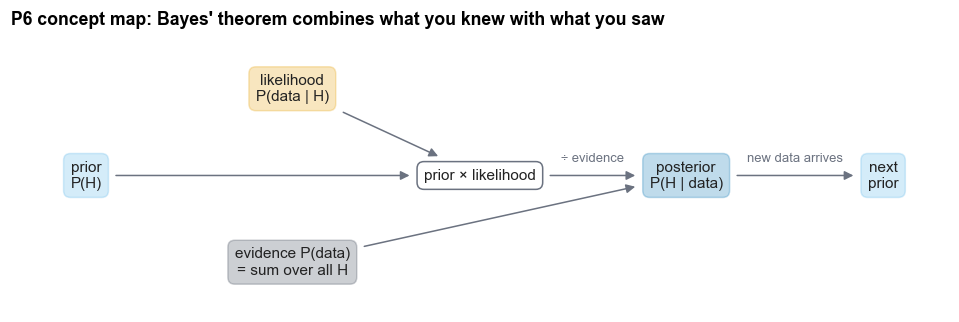

In [3]:
concept_map(
    {"prior": (0.08, 0.5, "prior\nP(H)", COL["prior"]),
     "lik": (0.30, 0.82, "likelihood\nP(data | H)", COL["likelihood"]),
     "un": (0.50, 0.5, "prior × likelihood", "white"),
     "ev": (0.30, 0.18, "evidence P(data)\n= sum over all H", COL["evidence"]),
     "post": (0.72, 0.5, "posterior\nP(H | data)", COL["posterior"]),
     "next": (0.93, 0.5, "next\nprior", COL["prior"])},
    [("prior", "un", ""), ("lik", "un", ""), ("un", "post", "÷ evidence"), ("ev", "post", ""),
     ("post", "next", "new data arrives")],
    title="P6 concept map: Bayes' theorem combines what you knew with what you saw")

**그림에서 볼 것**: 사전(하늘색)과 우도(주황)를 곱하고, 모든 가설에 대해 더한 값(증거, 진회색)으로 나누면 사후(파랑)가 됩니다. 새 데이터가 오면 이 사후가 다음 사전이 됩니다. 이 노트북 내내 이 네 색이 같은 뜻으로 나옵니다.

## 먼저 알아 둘 것

**조건부 확률**: $P(A\mid B) = \dfrac{P(A \cap B)}{P(B)}$. "B 가 일어난 경우만 놓고, 그중 A 도 일어난 비율"입니다. Stat 110 4강의 주제입니다 [2].

**전확률 법칙(law of total probability)**: 어떤 사건 $B$ 의 확률은, $B$ 가 일어날 수 있는 길(서로 겹치지 않는 경우 $A_i$)마다의 확률을 더한 것입니다. $P(B) = \sum_i P(B\mid A_i)P(A_i)$. Stat 110 5강의 주제입니다 [2]. 베이즈 정리의 분모(증거)가 이것입니다.

**기호 사전**

| 기호 | 읽는 법 | 뜻 |
|---|---|---|
| $P(H)$ | "가설 H 의 확률" | 데이터를 보기 **전** 믿음(사전확률, prior) |
| $P(H\mid D)$ | "D 일 때 H 의 확률" | 데이터를 본 **뒤** 믿음(사후확률, posterior) |
| $\propto$ | "비례한다" | 상수 배는 무시한다. 마지막에 합이 1 이 되게 나누면 됨 |
| odds | 오즈 | $P / (1 - P)$. 확률 0.2 는 오즈 0.25 |

## 1. 베이즈 정리를 1,000 명으로 읽기

**한 줄 정의**: 베이즈 정리는 "데이터를 본 뒤의 믿음 = 데이터를 보기 전 믿음 × 그 가설이 데이터를 설명하는 정도 ÷ 데이터가 나올 전체 확률"입니다 [1].

**왜 필요한가**: P5 의 우도는 "가설이 맞다면 이 데이터가 나올 확률"입니다. 우리가 알고 싶은 것은 반대 방향, "이 데이터를 봤을 때 가설이 맞을 확률"입니다. 둘은 다르고, 그 사이를 잇는 것이 베이즈 정리입니다.

**숫자로 따라가기**: 유병률 2%, 아픈 사람의 90% 를 잡아내고, 건강한 사람의 5% 를 잘못 양성으로 내는 검사입니다. 1,000 명이면

| | 아픔 (20 명) | 건강 (980 명) |
|---|---|---|
| 양성 | 18 (= 20 × 0.90) | 49 (= 980 × 0.05) |
| 음성 | 2 | 931 |

양성 67 명 중 실제 환자는 18 명이므로 $P(\text{아픔}\mid +) = 18/67 = 0.27$ 입니다.

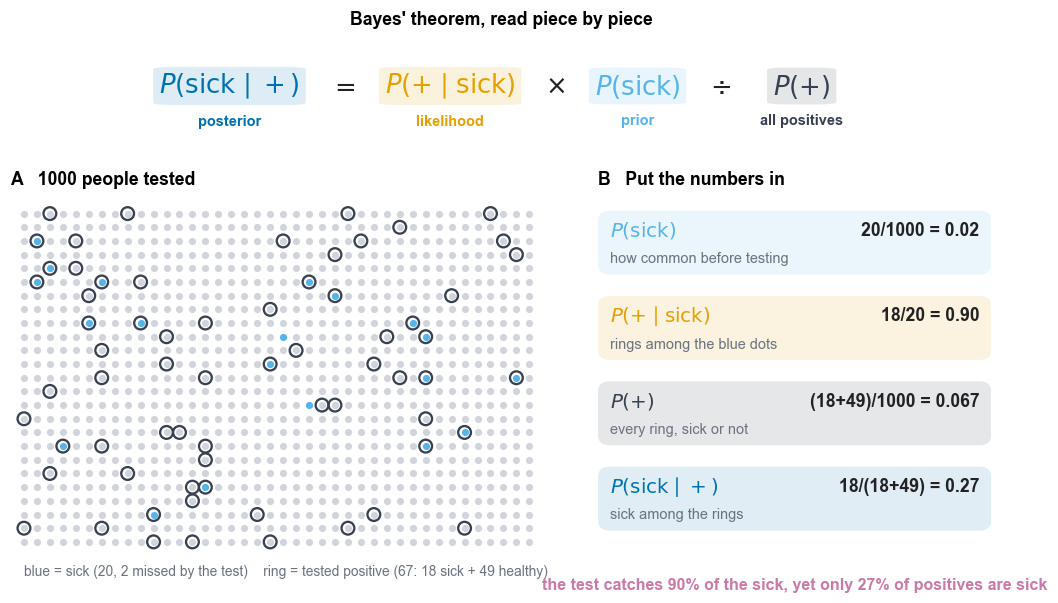

In [4]:
post = draw_bayes_reading()

**그림에서 볼 것**
- A: 파란 점 20 개가 환자, 고리가 양성입니다. 파란 점 중 2 개는 고리가 없습니다(검사가 놓친 환자). 고리 67 개 중 파란 점은 18 개뿐입니다.
- B: 위에서부터 사전(20/1000), 우도(파란 점 중 고리 18/20), 증거(모든 고리 67/1000), 사후(고리 중 파란 점 18/67)입니다. 수식 조각의 색과 상자 색이 짝을 이룹니다.
- 핵심 메시지: 90% 를 잡아내는 검사인데 양성 중 실제 환자는 27% 입니다. 환자가 드물어서 위양성 49 명이 진양성 18 명보다 많기 때문입니다.

**수식 풀어 읽기** (위 그림 맨 위 조각)

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $P(\text{sick}\mid +)$ | "양성일 때 아플 확률" | 사후: 양성 결과를 본 뒤의 믿음 | B 맨 아래 파란 상자, A 의 고리 중 파란 점 |
| $P(+\mid\text{sick})$ | "아플 때 양성일 확률" | 우도(민감도): 가설이 맞다면 이 결과가 나올 확률 | B 둘째 상자, A 의 파란 점 중 고리 |
| $P(\text{sick})$ | "아플 확률" | 사전(기저율): 검사 전 믿음 | B 첫째 상자, A 의 파란 점 전체 |
| $P(+)$ | "양성일 확률" | 증거: 아프든 아니든 양성이 나올 전체 확률. 전확률 법칙으로 $0.9\times0.02 + 0.05\times0.98$ | B 셋째 상자, A 의 고리 전체 |

**숫자 넣기**: $\dfrac{0.90 \times 0.02}{0.90\times0.02 + 0.05\times0.98} = \dfrac{0.018}{0.067} = 0.269$.

**시뮬레이션으로 확인**: 100 만 명을 무작위로 만들어 검사하고, 양성 중 환자 비율을 셉니다.

In [5]:
rng = np.random.default_rng(0)
N = 1_000_000
sick = rng.random(N) < 0.02
positive = np.where(sick, rng.random(N) < 0.90, rng.random(N) < 0.05)
p_sim = sick[positive].mean()
p_formula = bayes_post(0.02, 0.90, 0.05)
print(f"formula {p_formula:.4f}  simulation {p_sim:.4f}")
assert abs(p_sim - p_formula) < 0.005 and abs(post - 18 / 67) < 1e-12

formula 0.2687  simulation 0.2703


**직접 바꿔 보기**: 유병률을 20% 로 올리면 사후가 어떻게 될까요?

In [6]:
# draw_bayes_reading(prev=0.20)

## 2. 기저율을 잊으면 생기는 일

**한 줄 정의**: 기저율 오류(base-rate fallacy)는 사전확률을 무시하고 "검사가 정확하니 양성이면 거의 확실하다"고 읽는 실수입니다.

**왜 필요한가**: 시퀀싱에서 우리가 찾는 것(진짜 체세포 변이, 드문 생식세포 변이)은 대부분 유전체 자리에서 드뭅니다. 오류율이 낮은 검사라도 자리를 수십억 개 보면 오류가 진짜보다 많아질 수 있습니다.

**숫자로 따라가기**: 같은 검사(90%, 5%)에서

| 사전 P(아픔) | 사후 P(아픔 ∣ +) |
|---|---|
| 0.2% | 3.5% |
| 2% | 27% |
| 20% | 82% |

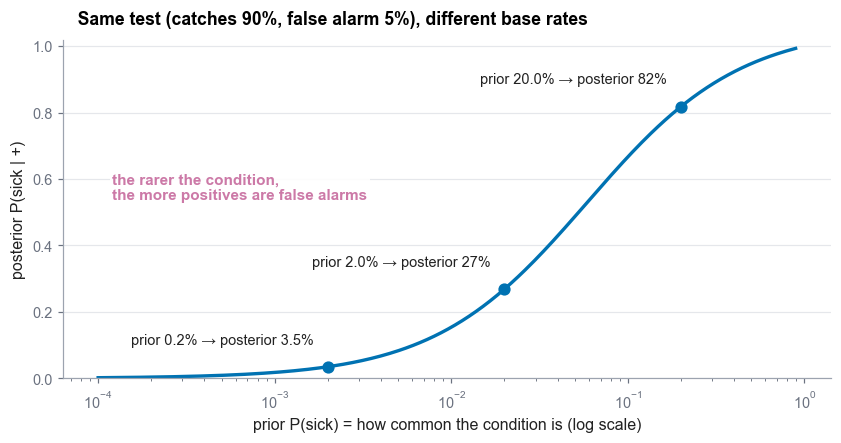

In [7]:
draw_base_rate()
for p, want in [(0.002, 0.035), (0.02, 0.269), (0.2, 0.818)]:
    assert abs(bayes_post(p, 0.9, 0.05) - want) < 0.001

**그림에서 볼 것**: 검사는 그대로인데 x 축(사전)만 바꿨습니다. 사전이 0.2% 면 양성의 96% 가 거짓 경보이고, 20% 면 82% 가 진짜입니다. 곡선 왼쪽 아래가 "드문 것을 찾을 때"의 영역입니다.

> **시퀀싱 데이터에서는**: Mutect2 의 germline 필터는 "이 변이가 생식세포(germline)일 사전확률"을 집단 allele 빈도 $f$ 로부터 $2f(1-f)$(이형접합), $f^2$(동형접합)로 두고, 체세포 변이의 사전확률 $\pi$ 와 함께 사후를 계산한다고 기술 문서에 적혀 있습니다 [8]. 짝 정상 시료가 없을 때(tumour-only)는 gnomAD 에 흔한 변이가 사전이 커서 germline 쪽으로 기웁니다. 반대로 깨끗한 짝 정상 시료가 있고 거기에 변이 read 가 하나도 없으면, 같은 변이라도 체세포 쪽이 됩니다(P9 연습 문제 2 에서 약 0.92). P9 에서 직접 계산합니다.

## 3. θ 가 연속일 때: 곡선끼리 곱하기

**한 줄 정의**: 모수 θ 가 0~1 사이 어떤 값이든 될 수 있으면, 사전과 사후는 곡선(확률 밀도)이고, 사후 곡선은 **사전 곡선과 우도 곡선을 점마다 곱한 것**을 넓이 1 로 맞춘 것입니다 [1].

**왜 필요한가**: VAF, purity, CCF 처럼 시퀀싱의 모수는 대부분 연속입니다. 가설이 두세 개일 때의 표가 곡선으로 바뀔 뿐, 계산은 같습니다.

**숫자로 따라가기**: read 10 개 중 변이 3 개(우도 꼭대기 0.3). 사전을 두 가지로 둡니다.
- 평평한 사전 Beta(1, 1): 0~1 어디든 같은 믿음 → 사후 꼭대기도 0.3
- "VAF 는 보통 0.1 근처" 라는 사전 Beta(2, 18) (평균 0.1) → 사후 꼭대기가 0.1 쪽으로 끌려 약 0.14

(Beta 분포는 0~1 사이 값의 분포입니다. P3 에서 모양을, P7 에서 자세히 다룹니다.)

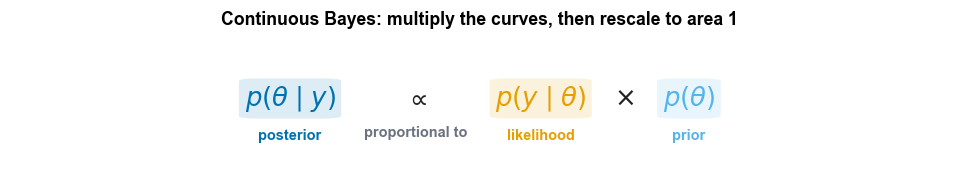

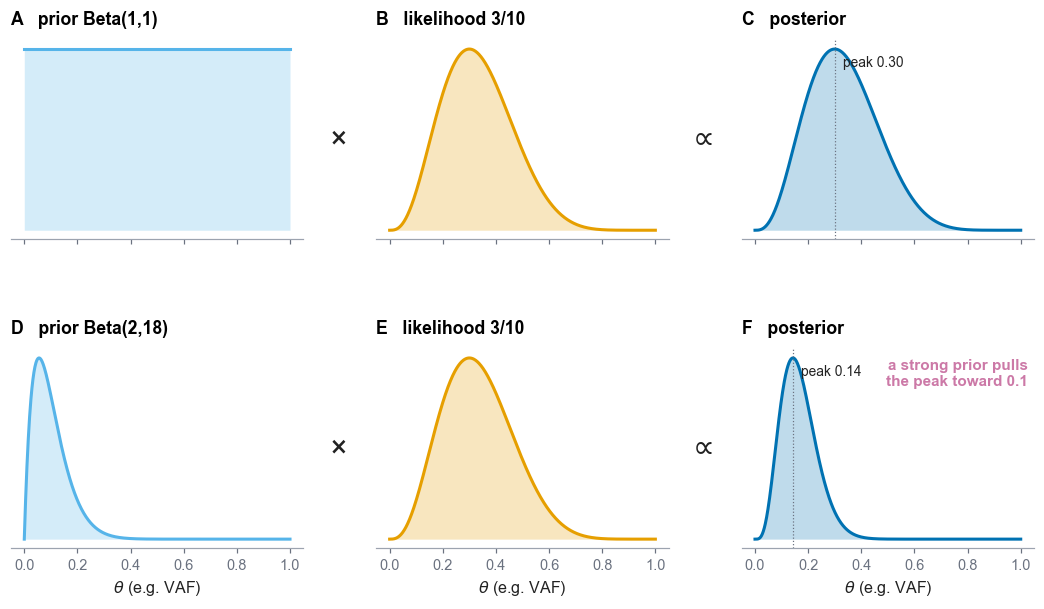

In [8]:
show_formula([
    (r"$p(\theta\mid y)$", COL["posterior"], "posterior"),
    (r"$\propto$", None, "proportional to"),
    (r"$p(y\mid\theta)$", COL["likelihood"], "likelihood"),
    (r"$\times$", None, None),
    (r"$p(\theta)$", COL["prior"], "prior"),
], title="Continuous Bayes: multiply the curves, then rescale to area 1")
draw_continuous()

**그림에서 볼 것**
- 윗줄(A→C): 평평한 사전(하늘색)에 우도(주황)를 곱하면 사후(파랑)는 우도와 같은 모양이고 꼭대기가 0.30 입니다.
- 아랫줄(D→F): 0.1 근처를 믿는 사전을 곱하면 사후 꼭대기가 0.14 로 끌려옵니다. 사후는 사전과 우도 사이 어딘가에 놓입니다.
- "∝" 는 곱한 뒤 넓이가 1 이 되도록 나눠야 한다는 뜻입니다. 그 나누는 수가 증거 $p(y) = \int p(y\mid\theta)p(\theta)d\theta$ 입니다.

**수식 풀어 읽기**

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $p(\theta\mid y)$ | "y 일 때 세타의 밀도" | 사후 곡선 | C, F 의 파란 곡선 |
| $p(y\mid\theta)$ | "세타일 때 y 의 확률" | 우도(P5 의 곡선) | B, E 의 주황 곡선 |
| $p(\theta)$ | "세타의 밀도" | 사전 곡선 | A, D 의 하늘색 곡선 |
| $\propto$ | 비례 | 점마다 곱한 뒤 전체 넓이로 나눔 | 곱한 곡선의 높이만 다시 맞춤 |

**시뮬레이션으로 확인**: 격자 위에서 곱해 나눈 사후가, P7 에서 배울 정확한 식(Beta(a + 3, b + 7))과 같은지 확인합니다.

In [9]:
th = np.linspace(0, 1, 2001); d = th[1] - th[0]
for a, b in [(1, 1), (2, 18)]:
    un = stats.beta.pdf(th, a, b) * stats.binom.pmf(3, 10, th)
    grid_post = un / (un.sum() * d)
    exact = stats.beta.pdf(th, a + 3, b + 7)
    err = np.max(np.abs(grid_post - exact))
    print(f"prior Beta({a},{b}): peak {th[np.argmax(grid_post)]:.3f}, max |grid - exact| = {err:.2e}")
    assert err < 1e-2 * exact.max()
assert abs(th[np.argmax(stats.beta.pdf(th, 5, 25))] - 4 / 28) < 1e-3     # Beta(2+3, 18+7) 의 꼭대기 = 4/28

prior Beta(1,1): peak 0.300, max |grid - exact| = 2.02e-12
prior Beta(2,18): peak 0.143, max |grid - exact| = 2.40e-14


**직접 바꿔 보기**: 사전을 Beta(20, 180) (평균 0.1, 훨씬 강한 믿음)으로 바꾸면 사후 꼭대기는 어디로 갈까요?

In [10]:
# draw_continuous(y=3, n=10, priors=((1, 1), (20, 180)))

## 4. 순차 업데이트: 어제의 사후가 오늘의 사전

**한 줄 정의**: 데이터가 차례로 들어오면, 앞 데이터로 얻은 사후를 다음 데이터의 사전으로 쓰면 됩니다. 결과는 데이터를 한꺼번에 넣은 것과 같습니다 [1].

**숫자로 따라가기** (BDA3 1.4 절의 혈우병 예 [1]): 오빠가 혈우병인 여성이 보인자(carrier)일 사전확률은 1/2 입니다. 보인자라면 아들 각각이 정상일 확률은 0.5, 아니라면 1 입니다.

| 단계 | 계산 | 보인자일 확률 |
|---|---|---|
| 사전 | — | 0.50 |
| 아들 둘 다 정상 | $\dfrac{0.25\times0.5}{0.25\times0.5 + 1\times0.5} = \dfrac{0.125}{0.625}$ | 0.20 |
| 셋째 아들도 정상 | $\dfrac{0.5\times0.20}{0.5\times0.20 + 1\times0.80}$ | 0.111 |

BDA3 는 같은 계산을 오즈로도 보입니다: 사전 오즈 1 × 우도비 0.25 = 사후 오즈 0.25 → 확률 0.2 [1].

**"차례로 = 한꺼번에"가 성립하는 조건**: 데이터 조각들이 θ(여기서는 보인자인지)를 알 때 서로 독립이어야 합니다. BDA3 는 이 예에서 두 아들의 결과가 "exchangeable and, conditional on the unknown θ, independent"라고 두고, 일란성 쌍둥이가 아니라고 가정합니다 [1]. read 에서는 이 가정이 자주 깨집니다. 같은 DNA 조각에서 나온 PCR 중복 read 나, 한 조각의 두 mate 가 겹친 자리는 같은 오류를 함께 가질 수 있습니다. Mutect2 기술 문서도 겹친 read 쌍에서는 "sequencing errors are independent, PCR errors are not"이라 우도를 그냥 곱하면 안 된다고 적고, 겹친 염기의 품질을 낮춰 맞춥니다 [8].

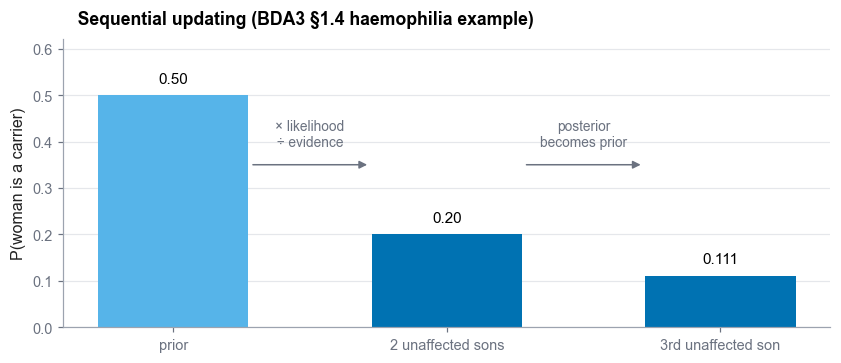

sequential 0.1111  all at once 0.1111


In [11]:
draw_sequential()
p = 0.5
for son in range(3):
    p = 0.5 * p / (0.5 * p + 1.0 * (1 - p))
    if son == 1:
        assert abs(p - 0.20) < 1e-12
batch = (0.5 ** 3 * 0.5) / (0.5 ** 3 * 0.5 + 1 * 0.5)          # 세 아들을 한꺼번에
print(f"sequential {p:.4f}  all at once {batch:.4f}")
assert abs(p - batch) < 1e-12 and abs(p - 1 / 9) < 1e-12

**그림에서 볼 것**: 하늘색(사전 0.5)에서 시작해, 정상인 아들이 한 명 늘 때마다 파란 막대가 내려갑니다(0.20 → 0.111). 셋째 아들 단계의 사전은 앞 단계의 사후 0.20 입니다. 한꺼번에 계산해도 1/9 = 0.111 로 같다는 것을 위 셀이 확인했습니다.

**오즈 형태의 베이즈 정리**: 가설이 둘일 때는 오즈로 쓰면 곱셈 하나가 됩니다. 로그를 씌우면 더하기가 됩니다.

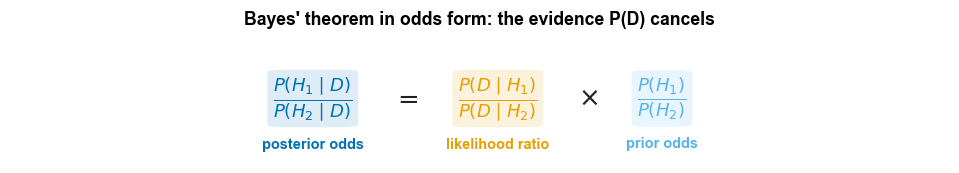

In [12]:
show_formula([
    (r"$\frac{P(H_1\mid D)}{P(H_2\mid D)}$", COL["posterior"], "posterior odds"),
    (r"$=$", None, None),
    (r"$\frac{P(D\mid H_1)}{P(D\mid H_2)}$", COL["likelihood"], "likelihood ratio"),
    (r"$\times$", None, None),
    (r"$\frac{P(H_1)}{P(H_2)}$", COL["prior"], "prior odds"),
], title="Bayes' theorem in odds form: the evidence P(D) cancels")

| 기호 | 소리 내어 읽기 | 뜻 |
|---|---|---|
| $P(H_1\mid D)/P(H_2\mid D)$ | 사후 오즈 | 데이터를 본 뒤 H₁ 이 H₂ 보다 몇 배 그럴듯한가 |
| $P(D\mid H_1)/P(D\mid H_2)$ | 우도비 | P5 의 그것. 데이터가 두 가설을 얼마나 가르는가 |
| $P(H_1)/P(H_2)$ | 사전 오즈 | 데이터 보기 전의 비 |

분모의 증거 $P(D)$ 는 두 가설에 똑같이 들어가서 지워집니다. 그래서 가설이 두 개일 때는 증거를 몰라도 됩니다.

## 5. 시퀀싱: genotype 사후확률

**한 줄 정의**: genotype 사후확률은 P5 의 genotype 우도에 "그 genotype 이 원래 얼마나 흔한가"(사전)를 곱해 나눈 것입니다.

**사전확률을 어디서 가져오나**: GATK 는 사람에 대해 heterozygosity 기본값을 $10^{-3}$ 으로 둡니다(`HomoSapiensConstants.SNP_HETEROZYGOSITY = 1e-3`) [5]. 소스 주석은 이 값이 "자리가 참조가 아닐 사전확률을 계산하는 데" 쓰이고, N 명이 모두 0/0 일 확률을 $1 - \sum_{i=1}^{2N} \text{het}/i$ 로 둔다고 적습니다 [5].

- **heterozygosity 의 뜻**: 한 사람의 genotype 이 이형접합일 확률이 아니라 집단유전학의 값입니다. 주석은 0.01 이면 "two randomly chosen chromosomes from the population … would differ from each other … at a rate of 1 in 100 bp"(집단에서 아무 염색체 둘을 골라 비교하면 100 bp 에 한 번 다름)라는 뜻이라고 적습니다 [5]. 기본값 0.001 은 1,000 bp 에 한 번입니다.
- **합의 각 항**: 이 합은 "그 자리의 변이 allele 이 표본의 2N 개 염색체 중 i 개에 있을" 확률을 i = 1, 2, … 에 대해 더한 것입니다(het/i 꼴이 어디서 나오는지는 이 노트북에서 확인하지 않았습니다). 한 사람(N = 1, 염색체 2 개)이면 i = 1 항 het/1 = 0.001 이 "변이 allele 1 개", i = 2 항 het/2 = 0.0005 가 "변이 allele 2 개"이고, 남은 $1 - 0.0015 = 0.9985$ 가 0 개입니다.
- 이 노트북은 이 세 값을 그대로 **P(0/1) = 0.001, P(1/1) = 0.0005, P(0/0) = 0.9985** 로 둡니다.

**실제 도구와 다른 점**: 같은 주석은 GATK 가 이 사전을 "자리가 다형성일 확률"을 정할 때만 쓰고, 출력하는 genotype likelihood 는 사후가 아니라 우도 그대로라고 분명히 적습니다 [5]. 아래 계산은 베이즈 정리를 보이려고 이 값을 한 사람의 genotype 사전처럼 쓴 **공부용 단순화**입니다.

**숫자로 따라가기** (P5 와 같은 read 10 개, 변이 3 개)

| | Q30 | Q10 |
|---|---|---|
| 사전 오즈 0/1 : 0/0 | $0.001/0.9985 = 10^{-3.0}$ | $10^{-3.0}$ |
| 우도비 0/1 : 0/0 (P5) | $10^{+6.0}$ | $10^{+0.3}$ |
| 사후 오즈 | $10^{+3.0}$ → P(0/1) ≈ 0.999 | $10^{-2.7}$ → P(0/1) ≈ 0.002 |

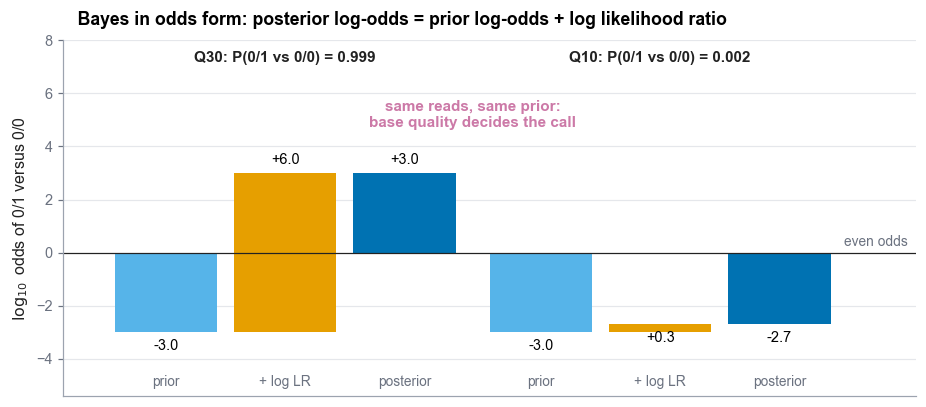

Q30 posterior: {'0/0': 0.001, '0/1': 0.999, '1/1': 0.0}
Q10 posterior: {'0/0': 0.998, '0/1': 0.002, '1/1': 0.0}
Q10 with errors spread over 3 bases: LR 27.7, P(0/1 vs 0/0) = 0.027


In [13]:
is_alt = np.array([False] * 7 + [True] * 3)
draw_odds_ladder(is_alt)
post30, _ = genotype_posterior(is_alt, 30); post10, _ = genotype_posterior(is_alt, 10)
print("Q30 posterior:", {g: round(v, 4) for g, v in post30.items()})
print("Q10 posterior:", {g: round(v, 4) for g, v in post10.items()})
assert max(post30, key=post30.get) == "0/1" and post30["0/1"] > 0.99
assert max(post10, key=post10.get) == "0/0" and post10["0/0"] > 0.99
lr3 = ((1 - 0.1 + 0.1 / 3) / 2) ** 10 / (0.9 ** 7 * (0.1 / 3) ** 3)      # 오류가 세 염기로 고르게(ε/3) 갈 때
odds3 = lr3 * GENO_PRIOR["0/1"] / GENO_PRIOR["0/0"]
print(f"Q10 with errors spread over 3 bases: LR {lr3:.1f}, P(0/1 vs 0/0) = {odds3 / (1 + odds3):.3f}")
assert abs(lr3 - 27.7) < 0.1 and abs(odds3 / (1 + odds3) - 0.027) < 0.001

**그림에서 볼 것**
- 왼쪽 묶음(Q30): 사전(하늘색, −3.0)에서 시작해 우도비(주황, +6.0)를 더하면 사후(파랑, +3.0)가 0 위로 올라갑니다. 0/1 이 0/0 보다 약 1,000 배 그럴듯합니다.
- 오른쪽 묶음(Q10): 같은 사전에 우도비가 +0.3 뿐이라 사후가 −2.7 로 여전히 0 아래입니다. 같은 "10 개 중 3 개"인데 0/0 으로 판정됩니다.
- 가로선 0 은 "두 genotype 이 반반"인 자리입니다. 로그 오즈에서는 베이즈 정리가 막대를 이어 쌓는 덧셈이 됩니다.
- 이 우도는 P5 의 **두 염기 가정**(틀린 염기는 늘 다른 쪽 allele 로 읽힘)을 따릅니다. 틀린 염기가 나머지 세 염기로 고르게 간다고(ε/3) 보면 Q10 의 우도비는 약 2.0 에서 27.7 로 커지지만, 사전 오즈 $10^{-3}$ 를 곱하면 P(0/1) 은 약 0.027 이라 여전히 0/0 입니다(위 출력).

**시뮬레이션으로 확인**: 사전대로 genotype 을 뽑고(대부분 0/0), 그 genotype 에서 Q10 read 10 개를 만든 뒤, "변이 3 개"가 나온 경우만 모아 실제로 0/1 이었던 비율을 셉니다. 이 비율이 위 사후 P(0/1 ∣ 정확히 이 read 수) 와 같아야 합니다. read 순서는 상관없으므로 "변이 개수 3"으로 조건을 겁니다.

In [14]:
rng = np.random.default_rng(3)
M = 4_000_000
geno = rng.choice(3, size=M, p=[GENO_PRIOR["0/0"], GENO_PRIOR["0/1"], GENO_PRIOR["1/1"]])   # 0: 0/0, 1: 0/1, 2: 1/1
e = phred_to_e(10)
p_alt_read = np.array([e, 0.5, 1 - e])[geno]                 # 두 염기 모형에서 read 가 변이로 보일 확률
n_alt = rng.binomial(10, p_alt_read)
sel = n_alt == 3
frac_het = np.mean(geno[sel] == 1)
print(f"sites with exactly 3/10 alt reads: {sel.sum():,};  truly 0/1 among them: {frac_het:.4f};  formula {post10['0/1']:.4f}")
assert abs(frac_het - post10["0/1"]) < 0.002

sites with exactly 3/10 alt reads: 229,102;  truly 0/1 among them: 0.0021;  formula 0.0020


**직접 바꿔 보기**: Q20 으로 바꾸거나, 사전을 "이 자리는 gnomAD 에 흔한 변이"처럼 P(0/1) = 0.3 으로 바꿔 보세요. 사전이 커지면 Q10 에서도 0/1 이 됩니다.

In [15]:
# post20, _ = genotype_posterior(is_alt, 20); print(post20)
# print(genotype_posterior(is_alt, 10, prior={"0/0": 0.6, "0/1": 0.3, "1/1": 0.1})[0])

> **시퀀싱 데이터에서는**: 사전은 "무엇을 찾는가"에 따라 바뀝니다. 생식세포 변이 호출은 집단의 heterozygosity 나 allele 빈도를, 체세포 변이 호출은 "체세포 변이가 생길 확률"을 사전으로 씁니다. Mutect2 기술 문서는 germline 필터에서 이 두 사전을 함께 쓴다고 설명합니다 [8]. 같은 read 라도 사전이 다르면 결론이 다르다는 것이 베이즈 방법의 장점이자, 사전을 잘 골라야 하는 이유입니다.

## 연습 문제

1. 같은 검사(90%, 5%)에서 유병률이 0.5% 면 양성일 때 아플 확률은?
2. 혈우병 예에서 셋째 아들이 **아프다면** 보인자일 사후확률은? (BDA3 1.4 절)
3. 두 가설의 사전 오즈가 1:99 이고 우도비가 50 이면 사후확률은?
4. Q30 read 10 개 중 변이 **1 개**만 있으면 0/1 과 0/0 중 무엇으로 판정될까요? (위 함수로 확인)

<details><summary>정답 보기</summary>

1. $0.9\times0.005/(0.9\times0.005 + 0.05\times0.995) = 0.0045/0.054 \approx 0.083$.
2. 1 입니다. 보인자가 아니면 아들이 아플 수 없으므로(돌연변이 무시) 우도가 0 이 되어 그 가설이 사라집니다. BDA3 도 같은 답을 적습니다.
3. 사후 오즈 $= 50/99 \approx 0.505$ → 확률 $0.505/1.505 \approx 0.336$.
4. 우도비 $L(0/1)/L(0/0) = 0.5^{10}/(0.999^9 \times 0.001) \approx 0.99$, 사전 오즈 $10^{-3}$ 이라 사후 오즈 $\approx 10^{-3}$ → 0/0. 변이 read 하나는 Q30 이라도 오류 한 번으로 충분히 설명됩니다.

</details>

In [16]:
a1 = bayes_post(0.005, 0.9, 0.05)
a3 = (50 / 99) / (1 + 50 / 99)
one_alt = np.array([False] * 9 + [True])
a4, ll4 = genotype_posterior(one_alt, 30)
lr4 = np.exp(ll4["0/1"] - ll4["0/0"])
print(f"1: {a1:.3f}   3: {a3:.3f}   4: LR {lr4:.2f}, posterior {max(a4, key=a4.get)}")
assert abs(a1 - 0.083) < 0.001 and abs(a3 - 0.336) < 0.001 and max(a4, key=a4.get) == "0/0" and abs(lr4 - 0.985) < 0.001

1: 0.083   3: 0.336   4: LR 0.99, posterior 0/0


## 정리

- 사후 = 사전 × 우도 ÷ 증거. 증거는 모든 가설에 대해 "사전 × 우도"를 더한 것(전확률 법칙)입니다.
- 사전(기저율)이 작으면 정확한 검사라도 양성의 대부분이 거짓일 수 있습니다.
- θ 가 연속이면 곡선을 점마다 곱하고 넓이 1 로 맞춥니다. 사후는 사전과 우도 사이에 놓입니다.
- 데이터를 차례로 넣어도, 한꺼번에 넣어도 사후는 같습니다.
- 가설이 둘이면 오즈 형태가 편합니다: 사후 로그 오즈 = 사전 로그 오즈 + 로그 우도비.
- genotype 호출에서 같은 read 라도 품질(우도)과 사전에 따라 판정이 바뀝니다.

다음 노트북(P7)에서는 θ 의 사전을 Beta 분포로 두면 사후도 Beta 가 되는 "켤레" 성질을 쓰고, 신용구간과 사후 예측을 다룹니다.

## 출처

| 번호 | 출처 | 이 노트북에서 쓴 곳 |
|---|---|---|
| [1] | Gelman A 외. *Bayesian Data Analysis*, 3rd ed. 비상업용 PDF: [책 누리집](https://sites.stat.columbia.edu/gelman/book/) | 1.3 절 베이즈 규칙과 사후 ∝ 사전 × 우도, 1.4 절 혈우병 예(0.20, 0.111, 오즈 형태, 셋째 아들이 아프면 1, p.8 "conditional on the unknown θ, independent") |
| [2] | Blitzstein J. Harvard Statistics 110 강의, [YouTube 재생목록](https://www.youtube.com/playlist?list=PL2SOU6wwxB0uwwH80KTQ6ht66KWxbzTIo) — [4강](https://www.youtube.com/watch?v=P7NE4WF8j-Q) "Conditional Probability", [5강](https://www.youtube.com/watch?v=JzDvVgNDxo8) "Conditioning Continued, Law of Total Probability" | 조건부 확률, 전확률 법칙 |
| [3] | Downey AB. *Think Bayes* 2nd ed., [2장 Bayes's Theorem](https://allendowney.github.io/ThinkBayes2/chap02.html) | 같이 볼 교재 |
| [4] | McElreath R. *Statistical Rethinking* 2023, [GitHub 강의표](https://github.com/rmcelreath/stat_rethinking_2023) 2강 | 같이 볼 강의 |
| [5] | GATK 4.7.0.0 소스. [`HomoSapiensConstants.java`](https://github.com/broadinstitute/gatk/blob/4.7.0.0/src/main/java/org/broadinstitute/hellbender/utils/variant/HomoSapiensConstants.java) (`SNP_HETEROZYGOSITY = 1e-3`), [`GenotypeCalculationArgumentCollection.java`](https://github.com/broadinstitute/gatk/blob/4.7.0.0/src/main/java/org/broadinstitute/hellbender/tools/walkers/genotyper/GenotypeCalculationArgumentCollection.java) (heterozygosity 주석) | 사전 0.001, $1-\sum\text{het}/i$, heterozygosity 의 뜻(100 bp 에 한 번), "genotype likelihood 는 사후가 아니다" |
| [6] | Li H. 2011. *Bioinformatics* 27(21):2987–2993. [doi:10.1093/bioinformatics/btr509](https://doi.org/10.1093/bioinformatics/btr509) | genotype 우도 식 (2) (P5 에서 가져옴) |
| [7] | Cock PJA 외. 2010. *Nucleic Acids Res* 38(6):1767–1771. [doi:10.1093/nar/gkp1137](https://doi.org/10.1093/nar/gkp1137) | Phred 점수 → 오류 확률 |
| [8] | GATK 개발팀. Mutect2 기술 문서 [`docs/mutect/mutect.tex`](https://github.com/broadinstitute/gatk/blob/4.7.0.0/docs/mutect/mutect.tex) (4.7.0.0), Germline Filter 절, read 쌍 겹침 단락 | 사전 $2f(1-f)$, $f^2$, 체세포 사전 $\pi$, "sequencing errors are independent, PCR errors are not" |

1,000 명 예, 기저율 표, 연속 사후, genotype 사후의 숫자와 시뮬레이션은 이 노트북에서 직접 계산한 결과입니다.